# 07. Evolutionary controller tuning

Original study laboratory. All generated data are synthetic.

Encode $(K_p,K_i)$ as bounded real values or 12-bit binary chromosomes.
Use tournament selection, crossover, mutation and elitism to minimize
$J=\mathrm{IAE}+0.03\sum_k|u_k-u_{k-1}|$. Equal population and generation
counts give equal numbers of objective evaluations, not equal wall-clock cost.
Report the seeded search and test its gains on a changed residence time.
A small outer search also tunes a MIMO MPC move penalty; it is not a claim
of a global optimum.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(7, ROOT / "laboratories/07-evolutionary-tuning/results")
print(json.dumps(result["summary"], indent=2))

{
  "real": {
    "parameters": [
      3.8100087691331614,
      0.7
    ],
    "fitness": 1.8203124209747872,
    "history": [
      1.9188149503223095,
      1.8423213475361402,
      1.8423213475361402,
      1.8305256526306108,
      1.8305256526306108,
      1.827172646372602,
      1.824956007577423,
      1.822207032967797,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872,
      1.8203124209747872
    ],
    "evaluations": 306,
    "encoding": "real",
    "seed": 42,
    "held_out_tau_14": {
      "iae": 2.314804263643065,
      "ise": 0.32945869759040725,
      "itae": 73.14885429826197,
      "control_energy": 26.52194432829843,
      "total_variation": 2.043068337686057,
      "constraint_violation": 0.0,
      "final_error": 0.002065923853395213
    }
  },
  "binary": {
    "parameters": [
      3.828717948717949,
    

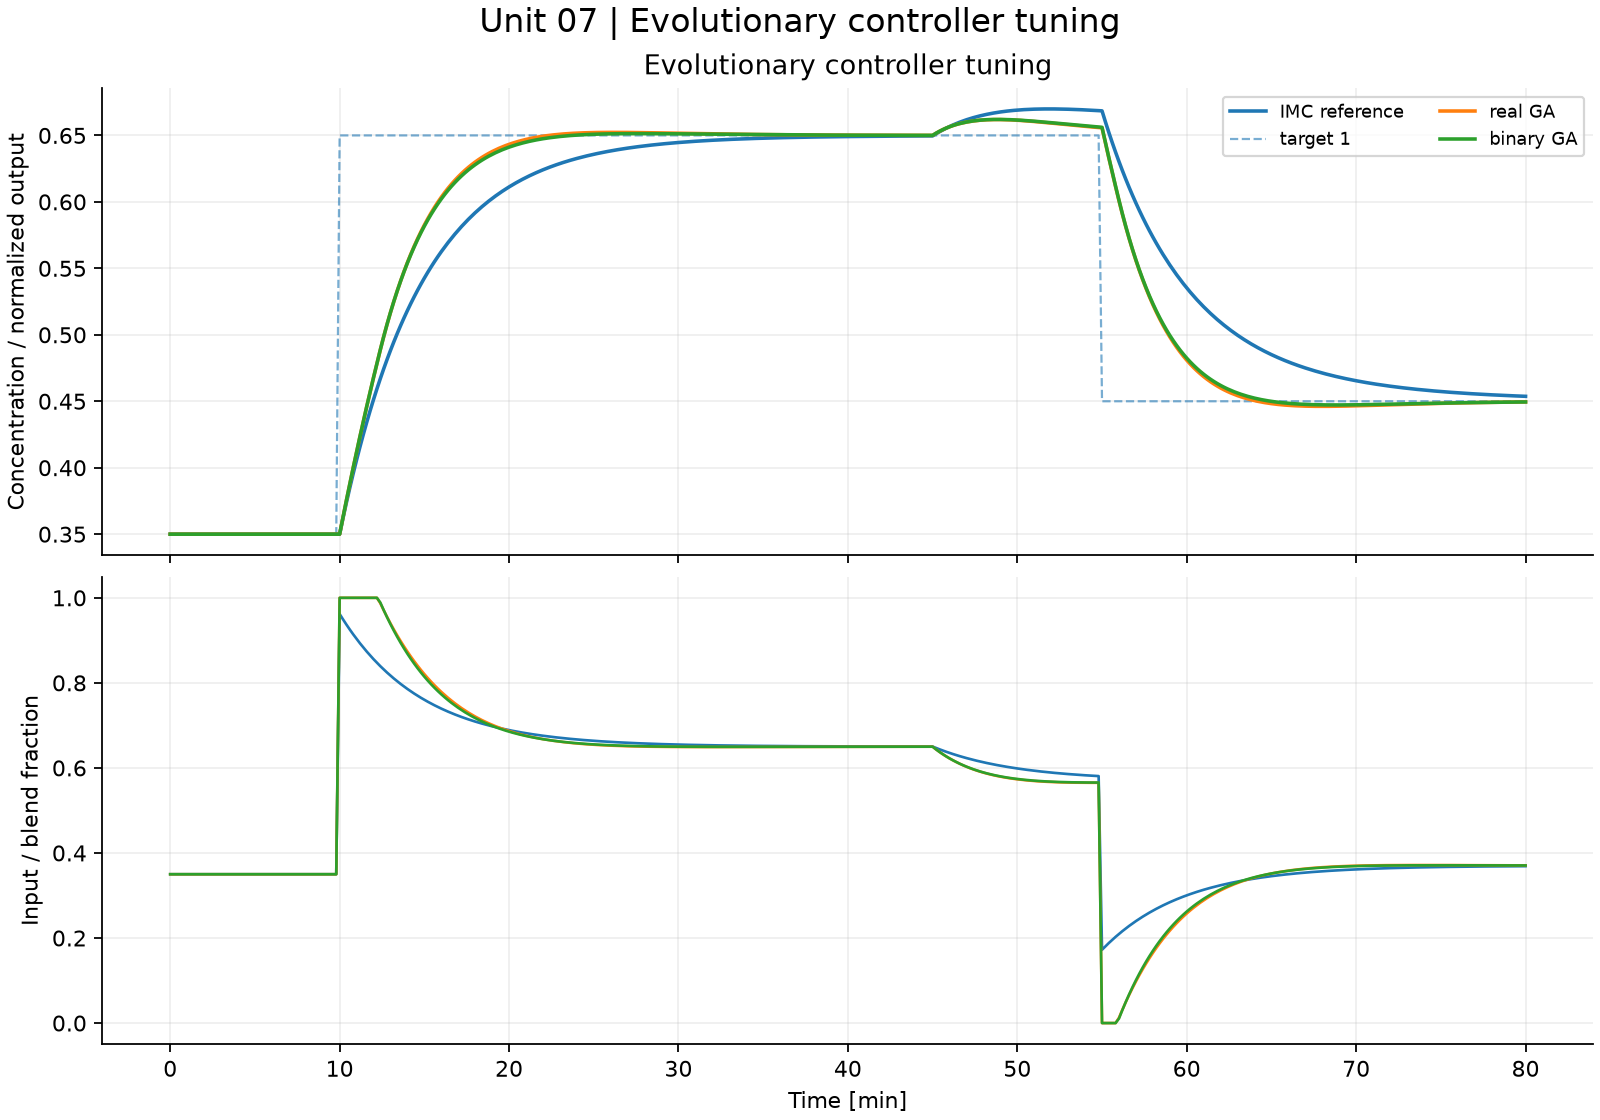

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/07-evolutionary-tuning/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](../../course/README.md), [worked problems](../../problem-sets/README.md) and [benchmark inventory](../../benchmarks/README.md) for the corresponding derivations and extensions.